# ASSIGNMENT 6 — Recurrent Neural Network (RNN)
**Họ và tên:** Trần Đình Hiếu  **MSV:** B23DCCE034

## Notebook 02 — RNN với **Keras** cho 2 bộ dữ liệu

Dùng **Keras 3** (API `keras.layers.SimpleRNN`). Keras 3 chạy được trên nhiều backend (TensorFlow, PyTorch, JAX); notebook đặt `KERAS_BACKEND="torch"` vì máy không có TensorFlow, nhưng **mã mô hình giữ nguyên** khi chuyển sang `"tensorflow"`.

Kiến trúc chính giống notebook scratch để so sánh công bằng:
`Input(T,1) → SimpleRNN(64, tanh) → Dense(1)` — loss MSE, Adam lr = 1e-3, batch 32, clipnorm = 1.0, EarlyStopping (patience 15, khôi phục trọng số tốt nhất).

In [1]:
import os
os.environ.setdefault('KERAS_BACKEND', 'torch')   # đổi thành 'tensorflow' nếu máy có TensorFlow
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)
print('Keras', keras.__version__, '| backend:', keras.backend.backend())

Keras 3.15.1 | backend: torch


## Dữ liệu & tiền xử lý (dùng chung cho cả 3 thư viện)

| Bộ dữ liệu | Nguồn | Chuỗi thời gian dự báo | Cửa sổ (window) |
|---|---|---|---|
| **E-commerce service process** | `olist_orders_dataset.csv` (Olist, Brazil) | Số đơn hàng được đặt mỗi ngày (15/01/2017 → 22/08/2018) | 14 ngày |
| **Stock** | `indexProcessed.csv` | Giá đóng cửa (USD) chỉ số NASDAQ – `IXIC` (2010 → 05/2021) | 30 phiên |

Các bước:
1. Gom chuỗi theo ngày (đơn hàng) / lọc chỉ số (cổ phiếu).
2. Chia **theo thời gian**: 80% đầu là train, 20% cuối là test (không xáo trộn để tránh rò rỉ thông tin tương lai).
3. Chuẩn hóa — chỉ dùng thống kê của tập train:
   * E-commerce: **Min-Max** về [0, 1].
   * Stock: **chuẩn hóa tương đối** $x'_k = (x_k / x_{t-1} - 1)/s$ (chia cho giá phiên cuối của cửa sổ, $s$ = độ lệch chuẩn lợi suất ngày trên train). Giá NASDAQ giai đoạn test cao hơn hẳn train nên Min-Max sẽ buộc mạng phải *ngoại suy* ngoài [0,1]; cách chuẩn hóa tương đối biến chuỗi thành dừng.
4. Tạo mẫu bằng **cửa sổ trượt**: $X = [x_{t-w}, \dots, x_{t-1}]$ → $y = x_t$ (bài toán *many-to-one*).
5. Đánh giá trên thang giá trị gốc bằng RMSE, MAE, MAPE, $R^2$ và so sánh với **baseline naive** ($\hat{x}_t = x_{t-1}$).

In [2]:
DATA_DIR = '.'          # thư mục chứa 2 file CSV
os.makedirs('figures', exist_ok=True)
os.makedirs('results', exist_ok=True)

def load_ecommerce():
    o = pd.read_csv(f'{DATA_DIR}/olist_orders_dataset.csv', parse_dates=['order_purchase_timestamp'])
    s = o.set_index('order_purchase_timestamp').resample('D').size().astype(float)
    s = s['2017-01-15':'2018-08-22']
    s.name = 'orders_per_day'
    return s

def load_stock(index='IXIC', start='2010-01-01'):
    d = pd.read_csv(f'{DATA_DIR}/indexProcessed.csv', parse_dates=['Date'])
    d = d[d['Index'] == index].set_index('Date').sort_index()
    s = d.loc[start:, 'CloseUSD'].astype(float)
    s.name = f'{index}_close_usd'
    return s

class MinMaxScaler1D:
    def fit(self, x):
        self.min, self.max = float(np.min(x)), float(np.max(x))
        return self
    def transform(self, x):
        return (np.asarray(x) - self.min) / (self.max - self.min)
    def inverse_transform(self, x):
        return np.asarray(x) * (self.max - self.min) + self.min

def prepare(series, window, scaling='minmax', train_ratio=0.8):
    # scaling='minmax'  : x' = (x - min) / (max - min), fit trên train.
    # scaling='relative': x' = (x / x_{t-1} - 1) / s  — chuẩn hóa theo giá cuối cửa sổ (s = độ lệch chuẩn lợi suất train),
    #                     giúp chuỗi không dừng (giá cổ phiếu) trở nên dừng và không phải ngoại suy.
    values = series.values.astype(np.float64)
    n_train = int(len(values) * train_ratio)
    target_idx = np.arange(window, len(values))
    base = values[target_idx - 1]                                   # giá trị ngay trước mục tiêu
    windows = np.stack([values[i - window:i] for i in target_idx])  # (N, T)
    targets = values[target_idx]
    is_train = target_idx < n_train
    if scaling == 'minmax':
        scaler = MinMaxScaler1D().fit(values[:n_train])
        X, y = scaler.transform(windows), scaler.transform(targets)
        inverse = lambda y_s, b: scaler.inverse_transform(y_s)
    else:
        s = float(np.std(targets[is_train] / base[is_train] - 1))
        X, y = (windows / base[:, None] - 1) / s, (targets / base - 1) / s
        inverse = lambda y_s, b: (np.asarray(y_s) * s + 1) * b
    test_base = base[~is_train]
    return dict(name=series.name, series=series, window=window, scaling=scaling,
                X_train=X[is_train][..., None], y_train=y[is_train][:, None],     # (N, T, 1), (N, 1)
                X_test=X[~is_train][..., None], y_test=y[~is_train][:, None],
                dates_test=series.index[target_idx[~is_train]],
                y_test_orig=targets[~is_train],
                naive_test=test_base,                                   # baseline: giá trị hôm trước
                to_original=lambda y_s: inverse(np.ravel(y_s), test_base))

def regression_metrics(y_true, y_pred):
    y_true, y_pred = np.ravel(y_true), np.ravel(y_pred)
    err = y_pred - y_true
    mask = y_true != 0
    return dict(RMSE=float(np.sqrt(np.mean(err ** 2))),
                MAE=float(np.mean(np.abs(err))),
                MAPE=float(np.mean(np.abs(err[mask] / y_true[mask])) * 100),
                R2=float(1 - np.sum(err ** 2) / np.sum((y_true - y_true.mean()) ** 2)))

DATASETS = {
    'ecommerce': prepare(load_ecommerce(), window=14, scaling='minmax'),
    'stock':     prepare(load_stock('IXIC'), window=30, scaling='relative'),
}
for k, d in DATASETS.items():
    print(f"{k:10s} | series={len(d['series'])} | X_train={d['X_train'].shape} | X_test={d['X_test'].shape}")

ecommerce  | series=585 | X_train=(454, 14, 1) | X_test=(117, 14, 1)
stock      | series=2871 | X_train=(2266, 30, 1) | X_test=(575, 30, 1)


## 1. Xây dựng mô hình

* `SimpleRNN(units)` = công thức $h_t=\tanh(W x_t + U h_{t-1} + b)$; mặc định `return_sequences=False` → chỉ trả về $h_T$ (many-to-one).
* `kernel` ↔ $W_{xh}$, `recurrent_kernel` ↔ $W_{hh}$ (Keras mặc định khởi tạo **orthogonal**), `bias` ↔ $b_h$.
* Hàm `build_model` cho phép đổi sang `LSTM`/`GRU` để so sánh thêm.

In [3]:
HIDDEN, LR, BATCH, EPOCHS, PATIENCE = 64, 1e-3, 32, 150, 15

def build_model(window, cell='SimpleRNN', hidden=HIDDEN, lr=LR):
    rnn_layer = getattr(layers, cell)
    model = keras.Sequential([
        keras.Input(shape=(window, 1)),
        rnn_layer(hidden, activation='tanh', name=cell.lower()),
        layers.Dense(1, name='output'),
    ], name=f'{cell}_regressor')
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr, clipnorm=1.0), loss='mse', metrics=['mae'])
    return model

build_model(14).summary()

Model: "SimpleRNN_regressor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simplernn (SimpleRNN)           │ (None, 64)             │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,289 (16.75 KB)

 Trainable params: 4,289 (16.75 KB)

 Non-trainable params: 0 (0.00 B)

Số tham số `SimpleRNN` = $H\cdot D + H\cdot H + H = 64 + 4096 + 64 = 4224$, khớp với công thức ở notebook 00.

## 2. Huấn luyện

`validation_split=0.1` của Keras lấy **10% cuối** của dữ liệu (đúng thứ tự thời gian) làm validation, giống notebook scratch.

In [4]:
def train_keras(d, cell='SimpleRNN', verbose=0):
    keras.utils.set_random_seed(SEED)
    model = build_model(d['window'], cell)
    es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True)
    t0 = time.time()
    h = model.fit(d['X_train'].astype('float32'), d['y_train'].astype('float32'),
                  validation_split=0.1, epochs=EPOCHS, batch_size=BATCH, shuffle=True,
                  callbacks=[es], verbose=verbose)
    train_time = time.time() - t0
    hist = {'train': h.history['loss'], 'val': h.history['val_loss']}
    print(f'{cell}: {len(hist["train"])} epochs, best val_loss = {min(hist["val"]):.5f}, {train_time:.1f} s')
    return model, hist, train_time

In [5]:
def plot_results(key, history, y_true, y_pred, lib, train_label='train', val_label='val'):
    d = DATASETS[key]
    fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={'width_ratios': [1, 2.3]})
    axes[0].plot(history['train'], label=train_label)
    if history.get('val'):
        axes[0].plot(history['val'], label=val_label)
    axes[0].set_title('Loss (MSE, dữ liệu đã chuẩn hóa)'); axes[0].set_xlabel('epoch'); axes[0].legend()
    axes[1].plot(d['dates_test'], y_true, label='Thực tế', color='black', lw=1.2)
    axes[1].plot(d['dates_test'], y_pred, label=f'Dự báo RNN ({lib})', color='tab:red', lw=1.2, alpha=.85)
    axes[1].set_title(f'{key}: dự báo 1 bước trên tập test'); axes[1].legend()
    plt.tight_layout()
    plt.savefig(f'figures/{lib}_{key}.png', dpi=110)
    plt.show()

def save_results(lib, key, metrics, naive, train_time, epochs, extra=None):
    out = dict(library=lib, dataset=key, metrics=metrics, naive_baseline=naive,
               train_time_sec=round(train_time, 2), epochs=epochs, **(extra or {}))
    with open(f'results/{lib}_{key}.json', 'w', encoding='utf-8') as f:
        json.dump(out, f, indent=2, ensure_ascii=False)
    return out

## 3. Dataset: E-commerce — số đơn hàng mỗi ngày (Olist)

SimpleRNN: 46 epochs, best val_loss = 0.00088, 7.8 s


,RMSE,MAE,MAPE,R2
Keras SimpleRNN,41.297,32.743,16.139,0.626
Naive (x_t-1),49.345,37.684,17.589,0.466


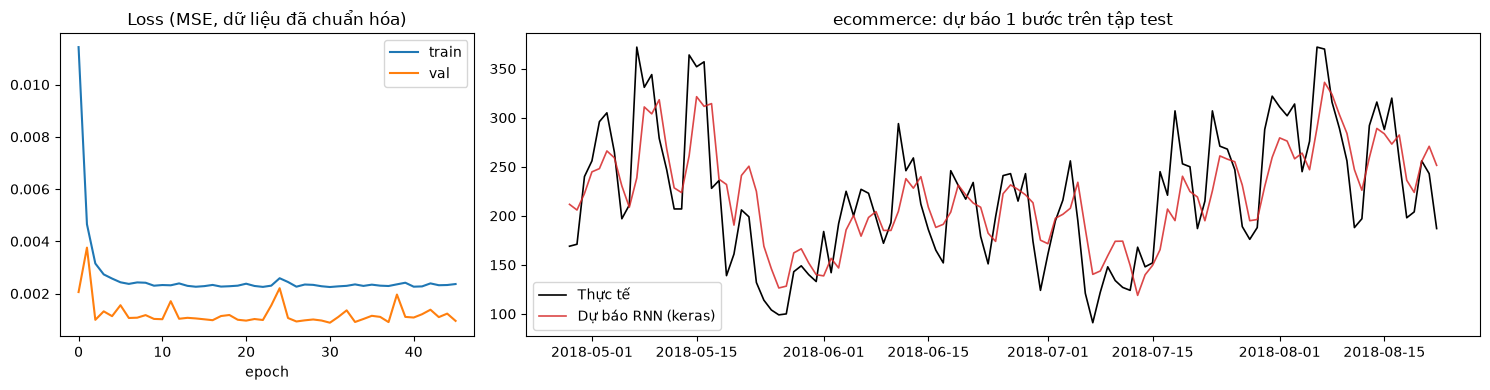

In [6]:
d = DATASETS['ecommerce']
model, hist, train_time = train_keras(d)
y_pred = d['to_original'](model.predict(d['X_test'].astype('float32'), verbose=0))
y_true = d['y_test_orig']
m_rnn = regression_metrics(y_true, y_pred)
m_naive = regression_metrics(y_true, d['naive_test'])
display(pd.DataFrame({'Keras SimpleRNN': m_rnn, 'Naive (x_t-1)': m_naive}).T.round(3))
plot_results('ecommerce', hist, y_true, y_pred, 'keras')
res_ecommerce = save_results('keras', 'ecommerce', m_rnn, m_naive, train_time, len(hist['train']), {'n_params': model.count_params()})

## 4. Dataset: Stock — NASDAQ (IXIC)

SimpleRNN: 30 epochs, best val_loss = 1.49574, 40.5 s


,RMSE,MAE,MAPE,R2
Keras SimpleRNN,159.924,108.225,1.103,0.994
Naive (x_t-1),158.243,107.550,1.103,0.995


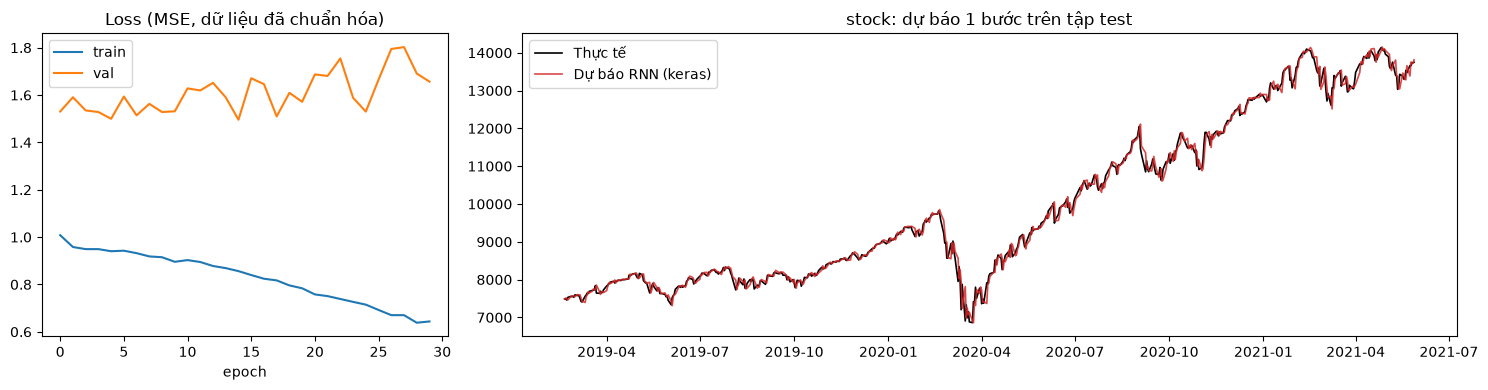

In [7]:
d = DATASETS['stock']
model, hist, train_time = train_keras(d)
y_pred = d['to_original'](model.predict(d['X_test'].astype('float32'), verbose=0))
y_true = d['y_test_orig']
m_rnn = regression_metrics(y_true, y_pred)
m_naive = regression_metrics(y_true, d['naive_test'])
display(pd.DataFrame({'Keras SimpleRNN': m_rnn, 'Naive (x_t-1)': m_naive}).T.round(3))
plot_results('stock', hist, y_true, y_pred, 'keras')
res_stock = save_results('keras', 'stock', m_rnn, m_naive, train_time, len(hist['train']), {'n_params': model.count_params()})

## 5. Mở rộng: so sánh SimpleRNN với LSTM và GRU (Keras)
Chỉ cần đổi tên lớp — minh họa ưu điểm của framework cấp cao.

In [8]:
rows = []
for key, d in DATASETS.items():
    for cell in ['SimpleRNN', 'LSTM', 'GRU']:
        model, hist, t = train_keras(d, cell)
        y_pred = d['to_original'](model.predict(d['X_test'].astype('float32'), verbose=0))
        rows.append({'dataset': key, 'cell': cell, 'params': model.count_params(), 'epochs': len(hist['train']),
                     'time_s': round(t, 1), **regression_metrics(d['y_test_orig'], y_pred)})
cmp = pd.DataFrame(rows)
cmp.to_csv('results/keras_cell_comparison.csv', index=False)
cmp.round(3)

SimpleRNN: 46 epochs, best val_loss = 0.00088, 7.8 s


LSTM: 18 epochs, best val_loss = 0.00162, 2.7 s


GRU: 16 epochs, best val_loss = 0.00160, 2.7 s


SimpleRNN: 30 epochs, best val_loss = 1.49574, 40.6 s


LSTM: 39 epochs, best val_loss = 1.48093, 45.6 s


GRU: 43 epochs, best val_loss = 1.48797, 54.0 s


,dataset,cell,params,epochs,time_s,RMSE,MAE,MAPE,R2
0,ecommerce,SimpleRNN,4289,46,7.8,41.297,32.743,16.139,0.626
1,ecommerce,LSTM,16961,18,2.7,58.862,49.154,25.053,0.241
2,ecommerce,GRU,12929,16,2.7,58.181,48.544,25.249,0.258
3,stock,SimpleRNN,4289,30,40.6,159.924,108.225,1.103,0.994
4,stock,LSTM,16961,39,45.6,161.621,108.281,1.111,0.994
5,stock,GRU,12929,43,54.0,156.374,106.186,1.087,0.995


## 6. Tổng kết

In [9]:
pd.DataFrame({k: {**v['metrics'], 'naive_RMSE': v['naive_baseline']['RMSE'], 'epochs': v['epochs'], 'time_s': v['train_time_sec']}
              for k, v in [('ecommerce', res_ecommerce), ('stock', res_stock)]}).T.round(3)

,RMSE,MAE,MAPE,R2,naive_RMSE,epochs,time_s
ecommerce,41.297,32.743,16.139,0.626,49.345,46.0,7.83
stock,159.924,108.225,1.103,0.994,158.243,30.0,40.51


**Nhận xét**
* Keras gói gọn mô hình trong vài dòng (`Sequential`, `compile`, `fit`); gradient, BPTT, Adam, clipping, early stopping đều có sẵn qua tham số/callback.
* Kết quả `SimpleRNN` tương đương bản scratch (cùng kiến trúc, cùng siêu tham số) — chứng tỏ bản tự cài đặt đúng.
* LSTM/GRU có nhiều tham số hơn (4× và 3× phần hồi quy) do có các cổng. Với cửa sổ ngắn (14–30 bước) lợi thế ghi nhớ dài hạn không phát huy: trên stock cả ba gần như bằng nhau (GRU nhỉnh hơn một chút); trên e-commerce (chỉ ~400 mẫu train) LSTM/GRU dừng sớm sau 16–18 epoch và kém SimpleRNN rõ rệt — mô hình nhiều tham số học chậm hơn trên dữ liệu nhỏ, cần tinh chỉnh thêm (lr, patience) mới so sánh công bằng được.